[![Obre a Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

# Nom i NIU

`Adrián Valverde Ambrosio` · `NIU: 1707952`

# Problema 4 · Model Evaluation

> **Pregunta forta**
> Quan dius que el teu model té un R² de 0.87, què has mesurat exactament: el model, o la
> sort del teu split?

Treballareu amb `train.csv` (Ames House Prices), el mateix fitxer de P1, P2 i de la sessió de
hands-on. L'objectiu és `SalePrice`: un problema de regressió, de cap a peus.

Aquesta entrega no va de trobar el millor model. Va de **poder defensar el número que
reporteu**.

## Com s'avalua (sobre 10)

| Exercici | Punts | Què es valora |
|---|---|---|
| Exercici 1 | 3 | Llegir corbes: diagnòstic correcte i decisió que se'n deriva |
| Exercici 2 | 3 | Grid contra Random: resultat, **temps mesurat**, i quan faríeu servir cada una |
| Exercici 3 | 2 | Les dues corbes sobre un problema de classificació, i què en concloeu |
| Exercici 4 | 2 | Protocol defensable i Model Card |

Cada exercici es tanca amb una Decisió (evidència · risc · límit).

**Regla d'or de sempre (§7.4)**, la de Problemes 1. Aquesta setmana també hi entren l'`alpha` i la `max_depth`, i sobretot això: dins de la validació creuada, cada `fit` només pot veure el seu fold d'entrenament.

*Referències: llibre §3.2.2 (validació, biaix-variança eq. 3.9, K-Fold eq. 3.10, Nested CV
Listing 3.5), §3.4.2 (selecció de models), §4.4.2 i §4.4.4 (arbres i poda) i §7.4 (leakage).*

## Preparació de dades (comuna)

`train.csv` ha d'estar al costat del notebook. Ens quedem només amb les variables numèriques,
com a la sessió de hands-on, perquè el focus és el protocol i no el preprocessament.

L'Exercici 3 fa servir un segon fitxer, `diabetes.csv`, que també ve dins del zip: és el
mateix de Problemes 3.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
                                     cross_val_score,
                                     GridSearchCV, RandomizedSearchCV,
                                     validation_curve, learning_curve)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge, LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from scipy.stats import loguniform

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

df = pd.read_csv('train.csv')
feature_cols = (df.select_dtypes('number')
                  .drop(columns=['Id', 'SalePrice'])
                  .columns.tolist())
X = df[feature_cols]
y = df['SalePrice']

X_tv, X_te, y_tv, y_te = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)

def make_reg(alpha=1.0):
    return Pipeline([('imputer', SimpleImputer(strategy='median')),
                     ('scaler', StandardScaler()),
                     ('model', Ridge(alpha=alpha, random_state=RANDOM_STATE))])

cv5 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f'{len(df)} cases, {len(feature_cols)} variables numèriques')
print(f'train+validation: {len(X_tv)}   test: {len(X_te)}')

1460 cases, 36 variables numèriques
train+validation: 1168   test: 292


## Exercici 1 (3 punts) · Llegir corbes que no has dibuixat

La cel·la següent genera **quatre corbes** de quatre configuracions que no coneixeu. No cal
que endevineu els paràmetres exactes: cal que en llegiu el diagnòstic.

Per a cadascuna, amb el protocol de tres moviments de la secció 10 del notebook de classe
(nivell, distància, pendent):

1. Quin és el problema dominant, biaix o variança? Amb quina evidència de la figura?
2. Recollir més dades ajudaria? Com ho sabeu mirant la corba?
3. Què canviaríeu: el model, les dades, o res?


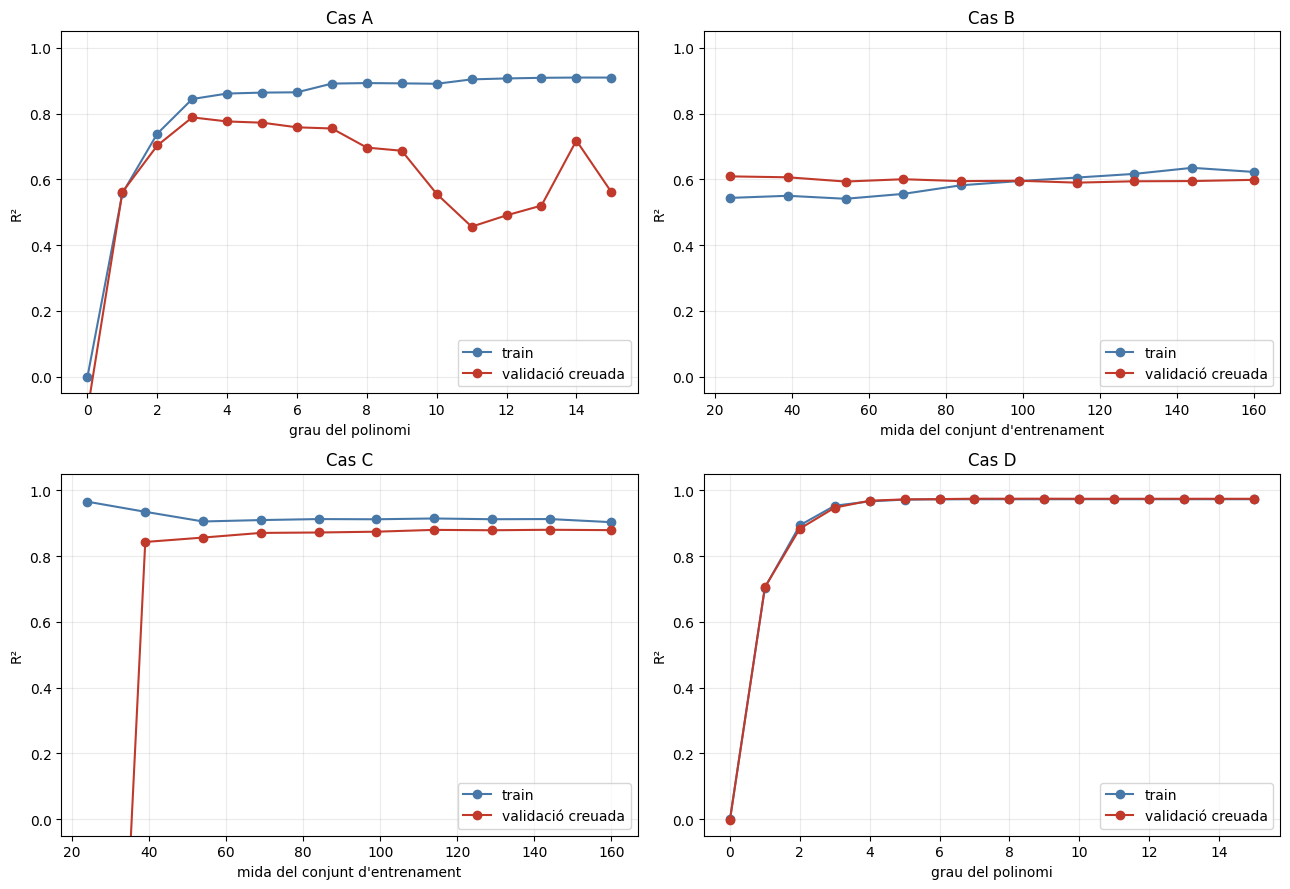

In [2]:
# Executeu aquesta cel·la i treballeu sobre les quatre figures que surten.
# (El codi genera les configuracions; l'exercici es llegir les corbes, no llegir el codi.)

def _dades(n, err=1.0, seed=1):
    rng = np.random.RandomState(seed)
    Xs = rng.rand(n, 1) ** 2
    ys = 10 - 1. / (Xs.ravel() + 0.1) + err * rng.randn(n)
    return Xs, ys

def _poli(d):
    return make_pipeline(PolynomialFeatures(d), LinearRegression())

def corbes_misterioses():
    casos = [('A', 'validacio', 30, 1.0, None), ('B', 'aprenentatge', 200, 1.0, 1),
             ('C', 'aprenentatge', 200, 1.0, 9), ('D', 'validacio', 400, 0.5, None)]
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for ax, (nom, tipus, n, err, grau) in zip(axes.ravel(), casos):
        Xs, ys = _dades(n, err=err, seed=7)
        if tipus == 'validacio':
            degs = np.arange(0, 16)
            tr, va = validation_curve(_poli(2), Xs, ys,
                                      param_name='polynomialfeatures__degree',
                                      param_range=degs, cv=5, scoring='r2')
            xs, xl = degs, 'grau del polinomi'
            t, v = np.median(tr, axis=1), np.median(va, axis=1)
        else:
            xs, tr, va = learning_curve(_poli(grau), Xs, ys, cv=5, scoring='r2',
                                        train_sizes=np.linspace(0.15, 1.0, 10))
            xl = "mida del conjunt d'entrenament"
            t, v = tr.mean(axis=1), va.mean(axis=1)
        ax.plot(xs, t, 'o-', color='#4878a8', label='train')
        ax.plot(xs, v, 'o-', color='#c0392b', label='validació creuada')
        ax.set_title(f'Cas {nom}'); ax.set_xlabel(xl); ax.set_ylabel('R²')
        ax.set_ylim(-0.05, 1.05); ax.grid(alpha=.25); ax.legend(loc='lower right')
    plt.tight_layout(); plt.show()

corbes_misterioses()

### Diagnòstic dels quatre casos

| Cas | Tipus de corba | Biaix o variança | Evidència a la figura | Més dades ajudarien? | Què canviaríeu |
|---|---|---|---|---|---|
| A | Validació (grau) | **Variança** a partir de grau ~4 (biaix a grau 0-1) | Màxim de validació 0.79 a grau 3; després train puja a 0.91 i validació cau i oscil·la (0.45 a grau 11, salts de 0.2 entre graus). Distància train-val de fins a 0.45. | Sí, per als graus alts: la inestabilitat ve de tenir poques dades (n = 30). | El model: quedar-me amb grau 3 (o regularitzar). |
| B | Aprenentatge (grau 1) | **Biaix** | Les dues corbes s'ajunten a ~0.6 des de 60 mostres i es queden planes (pendent ≈ 0). Distància ≈ 0. | No: les corbes ja s'han trobat i no pugen. | El model: més flexible (més grau / més variables). |
| C | Aprenentatge (grau 9) | **Variança amb poques dades**, després correcte | Amb < 40 mostres la validació s'enfonsa (R² < 0); a partir de 60 train ≈ 0.91 i validació ≈ 0.88, distància 0.03 i encara convergint lentament. | Poc: la distància ja és petita i el pendent és quasi pla; el sostre ≈ 0.9 és el soroll de les dades. | Res (o un grau més baix, que donaria el mateix amb menys risc). |
| D | Validació (grau) | **Cap** (a partir de grau 4) | Train i validació estan una sobre l'altra a tots els graus; pugen fins a 0.97 a grau 4-5 i es queden planes. Distància ≈ 0 fins i tot a grau 15. | No: no hi ha distància que tancar. | Res: triar el grau més simple de la zona plana (4-5). |

### Decisió (evidència · risc · límit)

- **Evidència:** la lectura es fa amb el **nivell** (on s'estabilitza la validació), la **distància** (train − val: gran = variança) i el **pendent** (si encara puja amb més dades). A i D són el mateix problema amb n = 30 i n = 400: amb poques dades el grau alt sobreajusta, amb moltes no.
- **Risc:** amb 30 mostres (A) i 5 folds cada fold té 6 punts: la corba de validació és sorollosa (el pic a grau 14 és soroll, no una millora).
- **Límit / no-ús:** el diagnòstic no diu si el sostre (0.6 a B, 0.9 a C) és soroll irreductible o falta d'informació; per saber-ho caldria conèixer el soroll de les dades.

## Exercici 2 (3 punts) · Grid Search contra Random Search

1. Munteu un `GridSearchCV` sobre `make_reg()` que busqui l'`alpha` de la Ridge en una
   graella de com a mínim 20 valors (`np.logspace`), amb `KFold` de 5 i `scoring='r2'`.
2. Munteu un `RandomizedSearchCV` amb **la meitat** d'ajustos, mostrejant `alpha` d'una
   distribució contínua (`loguniform`).
3. **Mesureu el temps de les dues cerques** amb `time` i ompliu aquesta taula:

   | cerca | ajustos | millor `alpha` | millor R² | segons |
   |---|---|---|---|---|
   | Grid | | | | |
   | Random | | | | |

4. La diferència de R² entre les dues, és més gran o més petita que la desviació entre folds
   del mateix model? Si és més petita, què vol dir això sobre la cerca que ha "guanyat"?
5. Dibuixeu, en un mateix gràfic, quins valors d'`alpha` ha provat cadascuna.
6. La secció 14 del notebook de classe imprimeix quant costa el Nested CV comparat amb una
   cerca simple. Poseu el vostre resultat al costat del que surti allà: què esteu disposats a
   pagar, i per a què?

### Hint · què val la pena buscar
Els hiperparàmetres no pesen igual. A la Ridge, el que mou el resultat és la força de la
regularització (`alpha`), i l'escala de les variables, que ja va dins del `Pipeline`. Si
busqueu sobre alguna cosa que no mou res, les dues cerques us donaran el mateix i no és
perquè les cerques siguin equivalents: és perquè la graella no anava enlloc.

### Prediu abans d'executar
Amb la meitat d'ajustos, espereu que Random trobi una configuració pitjor? Quant pitjor?

### Predicció (abans d'executar)
Amb la meitat d'ajustos, espero que Random trobi un α **pràcticament igual de bo** (diferència de R² < 0.005): amb un sol hiperparàmetre i una corba de R² suau al voltant de l'òptim, 10 punts mostrejats en escala logarítmica ja en deixen algun a prop del màxim.

In [3]:
# Grid Search sobre alpha: graella completa i temps
alphas_grid = np.logspace(-3, 4, 20)
grid = GridSearchCV(make_reg(), {'model__alpha': alphas_grid}, cv=cv5, scoring='r2')
t0 = time.perf_counter(); grid.fit(X_tv, y_tv); t_grid = time.perf_counter() - t0

# Random Search: la meitat d'ajustos, distribució contínua i temps
rand = RandomizedSearchCV(make_reg(), {'model__alpha': loguniform(1e-3, 1e4)}, n_iter=10,
                          cv=cv5, scoring='r2', random_state=RANDOM_STATE)
t0 = time.perf_counter(); rand.fit(X_tv, y_tv); t_rand = time.perf_counter() - t0

,ajustos,millor alpha,millor R²,desv. entre folds,segons
cerca,,,,,
Grid,100,143.84,0.7746,0.0757,1.60
Random,50,133.03,0.7745,0.0763,0.76


Diferència de R² Grid - Random: +0.0001


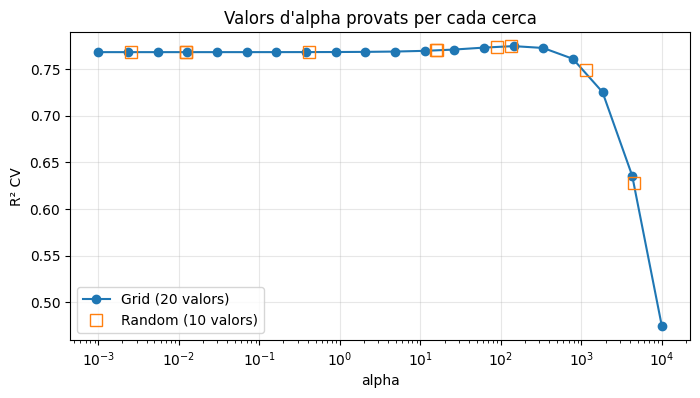

Grid simple: R² = 0.7746 en 1.60 s
Nested CV:   R² = 0.7651 ± 0.0734 en 7.64 s (4.8 vegades més)
Inflació de l'optimisme: +0.0095


In [4]:
# Comparació dels scores i dels temps
def resum(nom, s, t):
    i = s.best_index_
    return {'cerca': nom, 'ajustos': len(s.cv_results_['params']) * 5,
            'millor alpha': round(s.best_params_['model__alpha'], 2),
            'millor R²': round(s.best_score_, 4),
            'desv. entre folds': round(s.cv_results_['std_test_score'][i], 4),
            'segons': round(t, 2)}
taula = pd.DataFrame([resum('Grid', grid, t_grid), resum('Random', rand, t_rand)]).set_index('cerca')
display(taula)
print(f"Diferència de R² Grid - Random: {grid.best_score_ - rand.best_score_:+.4f}")

# Figura: quins valors d'alpha ha provat cada cerca
plt.figure(figsize=(8, 4))
plt.semilogx(grid.cv_results_['param_model__alpha'].astype(float), grid.cv_results_['mean_test_score'],
             'o-', label='Grid (20 valors)')
plt.semilogx(rand.cv_results_['param_model__alpha'].astype(float), rand.cv_results_['mean_test_score'],
             's', ms=9, mfc='none', label='Random (10 valors)')
plt.xlabel('alpha'); plt.ylabel('R² CV'); plt.legend(); plt.grid(alpha=.3)
plt.title('Valors d\'alpha provats per cada cerca'); plt.show()

# Cost del Nested CV (com a la secció 14 del notebook de classe)
inner_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1)
t0 = time.perf_counter()
nested = cross_val_score(GridSearchCV(make_reg(), {'model__alpha': alphas_grid}, cv=inner_cv, scoring='r2'),
                         X_tv, y_tv, cv=cv5, scoring='r2')
t_nested = time.perf_counter() - t0
print(f'Grid simple: R² = {grid.best_score_:.4f} en {t_grid:.2f} s')
print(f'Nested CV:   R² = {nested.mean():.4f} ± {nested.std():.4f} en {t_nested:.2f} s '
      f'({t_nested / t_grid:.1f} vegades més)')
print(f"Inflació de l'optimisme: {grid.best_score_ - nested.mean():+.4f}")

| cerca | ajustos | millor `alpha` | millor R² | segons |
|---|---|---|---|---|
| Grid | 100 (20 × 5 folds) | 143.8 | 0.7746 | 1.53 |
| Random | 50 (10 × 5 folds) | 133.0 | 0.7745 | 0.81 |

### Discussió · quan faríeu servir cada una

- **Diferència vs desviació entre folds:** Grid guanya per **0.0001** de R², i la desviació entre folds del mateix model és **0.076**: la diferència és 750 vegades més petita que el soroll del protocol. Vol dir que la cerca que "ha guanyat" no és millor: les dues han trobat la mateixa zona plana (α ≈ 130-150) i triar-ne una pel R² seria triar soroll.
- **Temps:** Random ha tardat la meitat (0.81 s vs 1.53 s), proporcional als ajustos.
- **Valors provats (figura):** la Grid recorre tota la graella de manera regular; la Random concentra punts a l'atzar però en escala logarítmica, i n'hi ha prou amb un parell a la zona bona.
- **Nested CV:** 7.7 s, **5 vegades** més que la Grid simple (1.53 s), i dona R² 0.765 contra 0.775: la cerca simple s'havia regalat **0.0095**. Pagaria aquest cost per **reportar el número final** (un cop), no per triar α. Per triar, la cerca simple és suficient.

**Quan triaria cadascuna:** **Grid** amb 1-2 hiperparàmetres i models ràpids (com aquí): és exhaustiva, reproduïble i fàcil de dibuixar. **Random** amb 3 o més hiperparàmetres o models lents (boosting, xarxes): amb el mateix pressupost explora més valors de cada paràmetre, sobretot quan només uns pocs importen.

### Decisió (evidència · risc · límit)

- **Evidència:** Grid i Random troben el mateix (0.7746 vs 0.7745) amb una desviació entre folds de 0.076; Random ho fa amb la meitat de temps.
- **Risc:** el `best_score_` d'una cerca és optimista perquè el mateix CV tria i mesura (+0.0095 segons el Nested CV).
- **Límit / no-ús:** aquesta comparació només val per a un hiperparàmetre amb una corba suau; amb espais grans o òptims estrets, Random pot no caure-hi.

## Exercici 3 (2 punts) · Les mateixes corbes, un altre problema

Fins ara totes les corbes que heu vist són de regressió. Aquí les fareu sobre un problema de
classificació de veritat: `diabetes.csv`, el de Problemes 3, que ja coneixeu.

1. Dibuixeu una **corba de validació** de la `max_depth` d'un `DecisionTreeClassifier`
   (profunditats d'1 a 16), amb `StratifiedKFold` i `scoring='roc_auc'`.
2. Dibuixeu una **corba d'aprenentatge** d'una regressió logística dins d'un `Pipeline`,
   amb la mateixa mètrica.
3. Llegiu-les amb el protocol de tres moviments (nivell, distància, pendent) i digueu quin
   problema té cadascun dels dos models, i què faríeu amb cadascun.

**Compte amb el nivell.** El $R^2$ val 0 quan el model és tan bo com predir la mitjana, o
sigui que porta la baseline dins de la definició. L'AUC no: val 0.5 quan el model ordena a
l'atzar. "Baix" no vol dir el mateix a les dues escales, i el vostre diagnòstic ho ha de
tenir en compte.

### Els arbres, al llibre
Al llibre, capítol 4. La poda per profunditat és la §4.4.2 i la corba que us demanem és la
§4.4.4 (figura 4.6), allà sobre dades sintètiques i aquí sobre pacients. Llegiu-vos aquelles
dues pàgines abans de començar.

### Hint · què controla la complexitat d'un arbre
La `max_depth` no és l'únic paràmetre que limita un arbre: `min_samples_leaf` i
`min_samples_split` fan una feina semblant, i sovint més suau. Aquí en demanem un de sol
perquè la corba sigui llegible, però si en voleu comentar un segon a la discussió, endavant.

### Prediu abans d'executar
Amb 768 pacients i 8 variables, quin dels dos models creieu que estarà limitat per la seva
pròpia rigidesa i quin per la seva flexibilitat?

### Predicció (abans d'executar)
La **regressió logística** (frontera lineal, 9 coeficients) estarà limitada per la seva **rigidesa** (biaix): amb 768 pacients ja haurà après el que pot. L'**arbre** estarà limitat per la seva **flexibilitat** (variança): amb profunditat gran memoritzarà les 614 pacients de train.

*Preparació:* zeros impossibles → NaN; split 80/20 estratificat i les corbes només sobre el 80%; imputació dins del `Pipeline`.

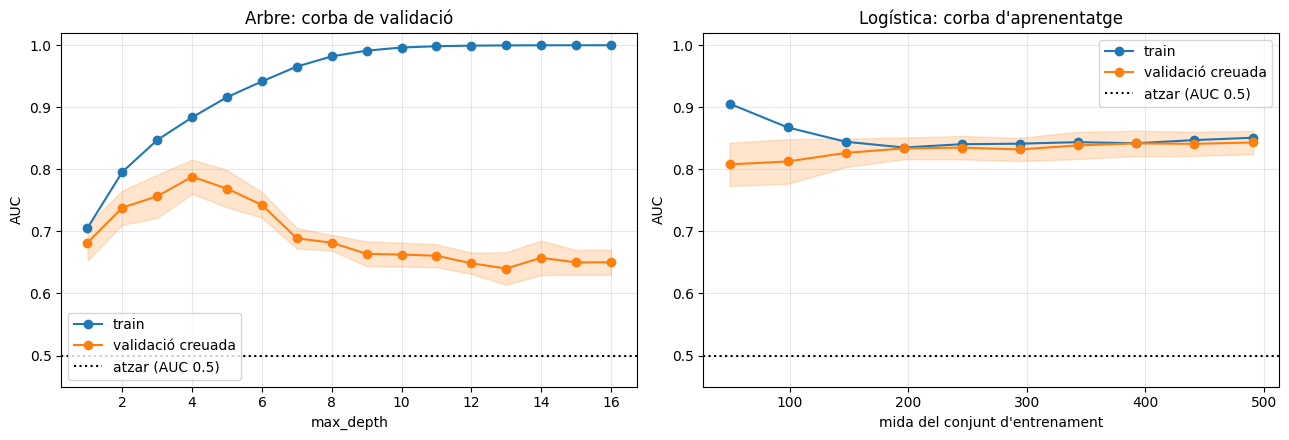

 max_depth  AUC train  AUC CV
         1      0.706   0.682
         2      0.796   0.738
         3      0.847   0.757
         4      0.884   0.788
         5      0.916   0.769
         6      0.942   0.743
         7      0.966   0.689
         8      0.982   0.682
         9      0.991   0.664
        10      0.996   0.663
        11      0.998   0.661
        12      0.999   0.649
        13      1.000   0.640
        14      1.000   0.657
        15      1.000   0.650
        16      1.000   0.650
 n train  AUC train  AUC CV
      49      0.906   0.808
      98      0.868   0.813
     147      0.845   0.826
     196      0.835   0.834
     245      0.841   0.835
     294      0.841   0.832
     343      0.844   0.839
     392      0.842   0.842
     441      0.847   0.841
     491      0.851   0.843


In [5]:
# diabetes.csv ha d'estar al costat del notebook, com a Problemes 3.
# Recordeu l'auditoria dels zeros impossibles abans de fer res.
dia = pd.read_csv('diabetes.csv')
clinical_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
dia[clinical_cols] = dia[clinical_cols].replace(0, np.nan)
Xd, yd = dia.drop(columns='Outcome'), dia['Outcome']
Xd_tv, Xd_te, yd_tv, yd_te = train_test_split(Xd, yd, test_size=0.2, stratify=yd, random_state=RANDOM_STATE)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Corba de validació: max_depth d'un DecisionTreeClassifier, AUC
depths = np.arange(1, 17)
arbre = make_pipeline(SimpleImputer(strategy='median'), DecisionTreeClassifier(random_state=RANDOM_STATE))
tr, va = validation_curve(arbre, Xd_tv, yd_tv, param_name='decisiontreeclassifier__max_depth',
                          param_range=depths, cv=skf, scoring='roc_auc')

# Corba d'aprenentatge: regressió logística, AUC
logit = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=1000))
sizes, ltr, lva = learning_curve(logit, Xd_tv, yd_tv, cv=skf, scoring='roc_auc',
                                 train_sizes=np.linspace(0.1, 1.0, 10), shuffle=True, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(depths, tr.mean(1), 'o-', label='train'); axes[0].plot(depths, va.mean(1), 'o-', label='validació creuada')
axes[0].fill_between(depths, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=.2, color='C1')
axes[0].set_xlabel('max_depth'); axes[0].set_title('Arbre: corba de validació')
axes[1].plot(sizes, ltr.mean(1), 'o-', label='train'); axes[1].plot(sizes, lva.mean(1), 'o-', label='validació creuada')
axes[1].fill_between(sizes, lva.mean(1) - lva.std(1), lva.mean(1) + lva.std(1), alpha=.2, color='C1')
axes[1].set_xlabel("mida del conjunt d'entrenament"); axes[1].set_title('Logística: corba d\'aprenentatge')
for ax in axes:
    ax.axhline(0.5, color='k', ls=':', label='atzar (AUC 0.5)'); ax.set_ylabel('AUC'); ax.set_ylim(0.45, 1.02)
    ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(pd.DataFrame({'max_depth': depths, 'AUC train': tr.mean(1), 'AUC CV': va.mean(1)}).round(3).to_string(index=False))
print(pd.DataFrame({'n train': sizes, 'AUC train': ltr.mean(1), 'AUC CV': lva.mean(1)}).round(3).to_string(index=False))

### Discussió · què li passa a cada model

**Arbre (corba de validació de `max_depth`):**
- *Nivell:* la validació té el màxim a **profunditat 4, AUC 0.788**.
- *Distància:* a profunditat 4 train = 0.884 (distància 0.10). A partir d'aquí train puja fins a 1.0 (memoritza) mentre validació baixa fins a 0.65: distància de 0.35.
- *Diagnòstic:* **biaix** a profunditat 1-2 (AUC val 0.68-0.74, train també baix) i **variança** a partir de 5. Què faria: podar a `max_depth` = 4 o fer servir `min_samples_leaf` (més suau), o un model de conjunt (random forest) per reduir la variança.

**Logística (corba d'aprenentatge):**
- *Nivell:* validació a **AUC 0.843** amb tot el train.
- *Distància:* train 0.851 vs val 0.843: **0.008**, pràcticament ajuntades.
- *Pendent:* la validació passa de 0.81 (49 pacients) a 0.84 (196) i després és quasi plana (+0.01 en 300 pacients més).
- *Diagnòstic:* **biaix** (model rígid). Més dades no ajudarien gaire. Què faria: més capacitat (interaccions, termes no lineals) o més variables informatives, no més pacients.

**Contra quin nivell he llegit l'AUC:** contra **0.5** (ordenar a l'atzar), no contra 0. Un AUC de 0.65 (arbre profund) sembla "alt" però només és 0.15 per sobre de l'atzar; la logística (0.84) supera l'arbre podat (0.79) clarament. La predicció es confirma.

### Decisió (evidència · risc · límit)

- **Evidència:** logística AUC CV 0.843 amb distància 0.008; arbre podat a profunditat 4, AUC CV 0.788. Em quedo amb la logística.
- **Risc:** la desviació entre folds és ~0.03-0.04 (banda de la figura), comparable amb diferències entre profunditats veïnes (3-5): el "4" és una zona, no un número exacte.
- **Límit / no-ús:** la conclusió és per a aquest dataset petit (614 pacients de train); amb moltes més dades un arbre profund o un conjunt podrien superar la logística.

## Exercici 4 (2 punts) · Protocol i Model Card

Ara ho heu de tancar com si ho haguéssiu de signar.

1. Trieu el vostre millor model i reporteu-ne el rendiment amb el protocol que pugueu
   defensar. Digueu **explícitament quin bucle ha triat els hiperparàmetres i quin els ha
   mesurat**, i quantes vegades heu obert el test.
2. Si els dos bucles han estat el mateix, digueu-ho i estimeu quant us heu regalat, fent
   servir el Nested CV com a la secció 14 del notebook de classe.
3. Ompliu la Model Card i enuncieu una condició de no-ús que surti d'alguna cosa que hàgiu
   **mesurat**, no d'una intuïció.

### Pregunta per raonar
Si el vostre R² al test surt més alt que el que la validació creuada predeia, és una bona
notícia? Què en concloeu sobre el proper conjunt de dades que us arribi?

In [6]:
# Model final, protocol declarat i test una sola vegada
from sklearn.model_selection import cross_val_predict

# Bucle que TRIA: GridSearchCV (KFold 5, intern) sobre X_tv -> alpha
# Bucle que MESURA: Nested CV (outer KFold 5) sobre X_tv; el test s'obre UNA vegada al final
print(f'alpha triat (grid sobre tot X_tv): {grid.best_params_["model__alpha"]:.2f}')
print(f'R² CV no imbricada (best_score_): {grid.best_score_:.4f}  <- el bucle que tria també mesura (optimista)')
print(f'R² Nested CV:                     {nested.mean():.4f} ± {nested.std():.4f}  <- estimació defensable')

# Baseline
base = cross_val_score(DummyRegressor(), X_tv, y_tv, cv=cv5, scoring='r2')
print(f'Baseline (mitjana) R² CV: {base.mean():.4f}')

# Límit mesurat: error segons el preu (prediccions fora de fold sobre X_tv)
pred_cv = cross_val_predict(grid.best_estimator_, X_tv, y_tv, cv=cv5)
trams = pd.qcut(y_tv, [0, .25, .5, .75, .9, 1.0])
lim = pd.DataFrame({'y': y_tv, 'err': np.abs(y_tv - pred_cv)}).groupby(trams, observed=True)['err'].agg(['count', 'mean'])
lim['error relatiu'] = lim['mean'] / pd.DataFrame({'y': y_tv}).groupby(trams, observed=True)['y'].mean()
lim.columns = ['cases', 'MAE ($)', 'MAE / preu mitjà']
display(lim.round(3))

# Test: una sola vegada
final = grid.best_estimator_            # reajustat amb tot X_tv
pred_te = final.predict(X_te)
print(f'TEST (1 vegada): R² = {r2_score(y_te, pred_te):.4f} | MAE = {mean_absolute_error(y_te, pred_te):,.0f} $')

alpha triat (grid sobre tot X_tv): 143.84
R² CV no imbricada (best_score_): 0.7746  <- el bucle que tria també mesura (optimista)
R² Nested CV:                     0.7651 ± 0.0734  <- estimació defensable
Baseline (mitjana) R² CV: -0.0016


,cases,MAE ($),MAE / preu mitjà
SalePrice,,,
"(34899.999, 130000.0]",293,17679.704,0.165
"(130000.0, 165000.0]",295,17732.721,0.121
"(165000.0, 214925.0]",288,19888.661,0.107
"(214925.0, 275950.0]",175,17358.156,0.072
"(275950.0, 745000.0]",117,53885.426,0.153


TEST (1 vegada): R² = 0.8206 | MAE = 22,367 $


### Protocol declarat

- **Model:** Ridge dins d'un `Pipeline` (imputació per mediana → `StandardScaler` → Ridge) sobre les 36 variables numèriques.
- **Bucle que tria:** `GridSearchCV` (KFold 5) sobre els 1168 casos de train+validation → α = 143.8.
- **Bucle que mesura:** **Nested CV** (5 folds externs × 5 interns): R² = **0.765 ± 0.073**. Els bucles són diferents: dins de cada fold extern, la cerca només veu el seu train.
- Si haguéssim fet servir el mateix bucle per triar i mesurar (`best_score_` = 0.7746), ens hauríem regalat **+0.0095** de R².
- **Test obert 1 vegada**, al final: **R² = 0.821**, MAE = 22,367 $.
- **Baseline** (`DummyRegressor`, la mitjana): R² CV = −0.002.

**Límit mesurat (no intuïció):** amb prediccions fora de fold, el MAE és de ~17-20 k$ per a cases fins a 276 k$ (7-16% del preu), però per al **10% de cases més cares (> 276 k$) el MAE puja a 53,900 $**, tres vegades més.

### Pregunta per raonar
Que el test (0.821) surti per sobre del Nested CV (0.765) **no és una bona notícia en si**: entra dins de la variabilitat entre folds (± 0.073), és a dir, hem tingut sort amb aquest split de 292 cases (probablement amb menys cases extremes). No hem de pujar l'expectativa: per al proper conjunt de dades, el número que defensaria és el del Nested CV, **0.77 ± 0.07**, no el del test.

## Mini Model Card (lliurable final)

| Camp | Resposta |
|---|---|
| Ús previst | Estimació orientativa del preu d'una casa a Ames (Iowa) a partir de les seves característiques numèriques. |
| Dades i període | `train.csv` d'Ames House Prices: 1460 vendes de 2006 a 2010, 36 variables numèriques. |
| Preparació sense leakage (què s'ajusta i amb què) | Imputació per mediana i `StandardScaler` dins del `Pipeline`: s'ajusten només amb el fold de train de cada CV i, al final, amb train+validation. |
| Model i hiperparàmetres, amb quin criteri triats | Ridge, α = 143.8, triat amb `GridSearchCV` (20 valors, KFold 5, R²). Random Search dona el mateix. |
| Protocol d'estimació (quin bucle tria i quin mesura) | Tria: GridSearchCV intern. Mesura: Nested CV (5 × 5) + un sol test. |
| Mètrica principal i per què | R² (variància del preu explicada; 0 = predir la mitjana), més MAE en dòlars per interpretar l'error. |
| Baseline superada | `DummyRegressor`: R² ≈ 0.00 → Ridge 0.765 (Nested CV). |
| Vegades que s'ha mirat el test | 1. |
| Resultat final | Nested CV R² = 0.765 ± 0.073; test R² = 0.821, MAE = 22,367 $. |
| Límit conegut (mesurat) | Per a cases > 276 k$ (10% més cares) el MAE és 53,900 $, tres vegades més que a la resta. |
| Condició de no-ús | No fer-lo servir per taxar cases de més de ~275 k$ (error mesurat 3 vegades més gran), ni fora d'Ames o del període 2006-2010. |

## Autoavaluació (opcional) · no compta per nota

Eina de teaching per situar-vos (rúbrica del curs). Objectiu personal: 8/8 i cap zero.

| Criteri | 2 | 1 | 0 |
|---|---|---|---|
| **Concepte** | connecto biaix, variança, complexitat i mida del train | només defineixo termes | els confonc |
| **Protocol** | el bucle que tria no és el que mesura; test obert un sol cop | parcial | leakage / trio amb test |
| **Interpretació** | llegeixo una corba pel nivell, la distància i el pendent | només descric la sortida | només un número |
| **Decisió** | evidència + risc + condició de no-ús | incompleta | no defensable |

## Declaració d'ús d'IA (obligatòria, no puntua)

| | La vostra resposta |
|---|---|
| Quina eina heu fet servir | Claude (Anthropic), assistent de programació. |
| Per a què exactament | Proposta i redacció del codi (cerques, nested CV, corbes) i esborrany de la lectura de les corbes i dels textos. |
| Com heu verificat el que us ha donat | Executant el notebook, mirant les figures i comprovant que els números del text coincideixen amb les sortides; revisant que el test només s'obre una vegada. |
| Què heu decidit vosaltres | El model final, el protocol (quin bucle tria i quin mesura) i la condició de no-ús. |
| Què no heu delegat | La revisió final i la defensa de les decisions. |